## 1. Import libraries and check GPU

In [ ]:
import os
import re
import json
import zipfile
import random
from pathlib import Pathss

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive and extract the dataset ZIP

In [8]:
from google.colab import drive
drive.mount("/content/drive")

# Upload your ZIP into MyDrive/TrafficSignProject first.
# This matches the downloaded filename shown in your screenshot.
ZIP_PATH = Path("/content/drive/MyDrive/TrafficSignProject/archive (3).zip")

# If you renamed the ZIP, change only ZIP_PATH above, for example:
# ZIP_PATH = Path("/content/drive/MyDrive/TrafficSignProject/gtsrb_dataset.zip")

DATA_DIR = Path("/content/traffic_sign_dataset")
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Dataset ZIP not found: {ZIP_PATH}\n"
        "Upload the ZIP to MyDrive/TrafficSignProject or update ZIP_PATH in this cell."
    )

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    bad_file = zip_ref.testzip()
    if bad_file is not None:
        raise RuntimeError(f"The ZIP file appears damaged: {bad_file}")
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted to:", DATA_DIR)
print("Top-level entries:", [p.name for p in DATA_DIR.iterdir()][:20])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset extracted to: /content/traffic_sign_dataset
Top-level entries: ['train', 'Train', 'meta', 'Meta.csv', 'Test.csv', 'Meta', 'Train.csv', 'Test', 'test']


## 3. Find Train.csv and Test.csv, then inspect the annotations

In [10]:
def find_file_case_insensitive(root, target_name):
    matches = [p for p in Path(root).rglob("*") if p.is_file() and p.name.lower() == target_name.lower()]
    if not matches:
        raise FileNotFoundError(f"Could not find {target_name} inside {root}")
    # Prefer the file that sits nearest the extracted dataset root.
    return sorted(matches, key=lambda p: len(p.parts))[0]

TRAIN_CSV = find_file_case_insensitive(DATA_DIR, "Train.csv")
TEST_CSV = find_file_case_insensitive(DATA_DIR, "Test.csv")
DATASET_ROOT = TRAIN_CSV.parent

print("Dataset root:", DATASET_ROOT)
print("Train CSV:", TRAIN_CSV)
print("Test CSV:", TEST_CSV)

# sep=None lets pandas infer comma- or semicolon-separated annotation files.
train_df = pd.read_csv(TRAIN_CSV, sep=None, engine="python", skipinitialspace=True)
test_df = pd.read_csv(TEST_CSV, sep=None, engine="python", skipinitialspace=True)

print("Training rows and columns:", train_df.shape)
print("Testing rows and columns:", test_df.shape)
print("Training columns:", train_df.columns.tolist())
display(train_df.head())
display(test_df.head())


Dataset root: /content/traffic_sign_dataset
Train CSV: /content/traffic_sign_dataset/Train.csv
Test CSV: /content/traffic_sign_dataset/Test.csv
Training rows and columns: (39209, 8)
Testing rows and columns: (12630, 8)
Training columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png


## 4. Prepare column names and validate labels

In [11]:
def normalize_column_name(name):
    """Make names such as 'Roi.X1', 'ROI X1', and 'roi_x1' comparable."""
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def get_column_map(df):
    return {normalize_column_name(col): col for col in df.columns}


def choose_column(df, possible_names, required=True):
    col_map = get_column_map(df)
    for name in possible_names:
        key = normalize_column_name(name)
        if key in col_map:
            return col_map[key]
    if required:
        raise ValueError(
            f"Could not find any of these columns: {possible_names}. "
            f"Found columns: {df.columns.tolist()}"
        )
    return None

PATH_COL = choose_column(train_df, ["Path", "Filename", "Image"])
CLASS_COL = choose_column(train_df, ["ClassId", "ClassID", "Label", "Class"])
ROI_X1_COL = choose_column(train_df, ["Roi.X1", "ROI.X1", "RoiX1"], required=False)
ROI_Y1_COL = choose_column(train_df, ["Roi.Y1", "ROI.Y1", "RoiY1"], required=False)
ROI_X2_COL = choose_column(train_df, ["Roi.X2", "ROI.X2", "RoiX2"], required=False)
ROI_Y2_COL = choose_column(train_df, ["Roi.Y2", "ROI.Y2", "RoiY2"], required=False)

print("Image path column:", PATH_COL)
print("Class column:", CLASS_COL)
print("ROI columns:", ROI_X1_COL, ROI_Y1_COL, ROI_X2_COL, ROI_Y2_COL)
print("Number of classes in training CSV:", train_df[CLASS_COL].nunique())
print("Class IDs:", sorted(train_df[CLASS_COL].astype(int).unique().tolist()))

# GTSRB contains class IDs from 0 through 42.
assert train_df[CLASS_COL].notna().all(), "Missing class labels exist in Train.csv."
assert train_df[CLASS_COL].astype(int).between(0, 42).all(), "Unexpected class IDs found."


Image path column: Path
Class column: ClassId
ROI columns: Roi.X1 Roi.Y1 Roi.X2 Roi.Y2
Number of classes in training CSV: 43
Class IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42]


## 5. Define the 43 traffic-sign class names

In [12]:
CLASS_NAMES = [
    "Speed limit (20 km/h)", "Speed limit (30 km/h)", "Speed limit (50 km/h)",
    "Speed limit (60 km/h)", "Speed limit (70 km/h)", "Speed limit (80 km/h)",
    "End of speed limit (80 km/h)", "Speed limit (100 km/h)", "Speed limit (120 km/h)",
    "No passing", "No passing for heavy vehicles", "Right-of-way at next intersection",
    "Priority road", "Give way", "Stop", "No vehicles", "Heavy vehicles prohibited",
    "No entry", "General caution", "Dangerous curve left", "Dangerous curve right",
    "Double curve", "Bumpy road", "Slippery road", "Road narrows on right", "Road work",
    "Traffic signals", "Pedestrians", "Children crossing", "Bicycles crossing",
    "Beware of ice/snow", "Wild animals crossing", "End of speed and passing limits",
    "Turn right ahead", "Turn left ahead", "Ahead only", "Straight or right",
    "Straight or left", "Keep right", "Keep left", "Roundabout mandatory",
    "End of no passing", "End of no passing for heavy vehicles"
]

NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 32

assert NUM_CLASSES == 43
print("Number of output classes:", NUM_CLASSES)


Number of output classes: 43


## 6. Load images, crop the ROI, and resize to 32 × 32

The CSV includes `Roi.X1`, `Roi.Y1`, `Roi.X2`, and `Roi.Y2`, which mark the traffic-sign region in each image. We crop this region before resizing. The function below reads the image paths from the CSV, rather than assuming every image has the same folder path.

In [13]:
def resolve_image_path(relative_path):
    # Paths in the CSV look like Train/20/image.png or Test/image.png.
    relative_path = str(relative_path).strip().replace("\\", "/").lstrip("/")
    candidate = DATASET_ROOT / relative_path
    if candidate.exists():
        return candidate

    candidate = DATA_DIR / relative_path
    if candidate.exists():
        return candidate

    # Some ZIPs contain one extra parent directory; this fallback tries the same relative path.
    for base in DATA_DIR.rglob(Path(relative_path).name):
        if base.is_file() and relative_path.replace("\\", "/").endswith(base.name):
            return base

    raise FileNotFoundError(f"Image path from CSV could not be found: {relative_path}")


def load_images(dataframe, description="Loading images"):
    """Return image array (uint8) and integer labels from a CSV dataframe."""
    column_map = get_column_map(dataframe)
    path_col = choose_column(dataframe, ["Path", "Filename", "Image"])
    class_col = choose_column(dataframe, ["ClassId", "ClassID", "Label", "Class"], required=False)
    if class_col is None:
        raise ValueError("This CSV does not have class labels, so it cannot be used for supervised evaluation.")

    roi_columns = {
        "x1": choose_column(dataframe, ["Roi.X1", "ROI.X1", "RoiX1"], required=False),
        "y1": choose_column(dataframe, ["Roi.Y1", "ROI.Y1", "RoiY1"], required=False),
        "x2": choose_column(dataframe, ["Roi.X2", "ROI.X2", "RoiX2"], required=False),
        "y2": choose_column(dataframe, ["Roi.Y2", "ROI.Y2", "RoiY2"], required=False),
    }
    use_roi = all(value is not None for value in roi_columns.values())

    images = []
    labels = []
    paths = []
    rows = dataframe[[path_col, class_col] + [c for c in roi_columns.values() if c is not None]].to_dict("records")

    for row in tqdm(rows, desc=description):
        image_path = resolve_image_path(row[path_col])
        with Image.open(image_path) as opened_image:
            image = opened_image.convert("RGB")

        if use_roi:
            width, height = image.size
            x1 = max(0, min(width, int(float(row[roi_columns["x1"]]))))
            y1 = max(0, min(height, int(float(row[roi_columns["y1"]]))))
            x2 = max(0, min(width, int(float(row[roi_columns["x2"]])) + 1))
            y2 = max(0, min(height, int(float(row[roi_columns["y2"]])) + 1))
            if x2 > x1 and y2 > y1:
                image = image.crop((x1, y1, x2, y2))

        image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        images.append(np.asarray(image, dtype=np.uint8))
        labels.append(int(row[class_col]))
        paths.append(str(image_path))

    X = np.stack(images)
    y = np.asarray(labels, dtype=np.int64)
    return X, y, paths

X_train_all_raw, y_train_all, train_image_paths = load_images(train_df, "Training images")
print("Training image array shape:", X_train_all_raw.shape)
print("Training label array shape:", y_train_all.shape)
print("Pixel range before normalization:", X_train_all_raw.min(), "to", X_train_all_raw.max())


Training images:   0%|          | 0/39209 [00:00<?, ?it/s]

Training image array shape: (39209, 32, 32, 3)
Training label array shape: (39209,)
Pixel range before normalization: 0 to 255


## 7. Explore class distribution and sample images

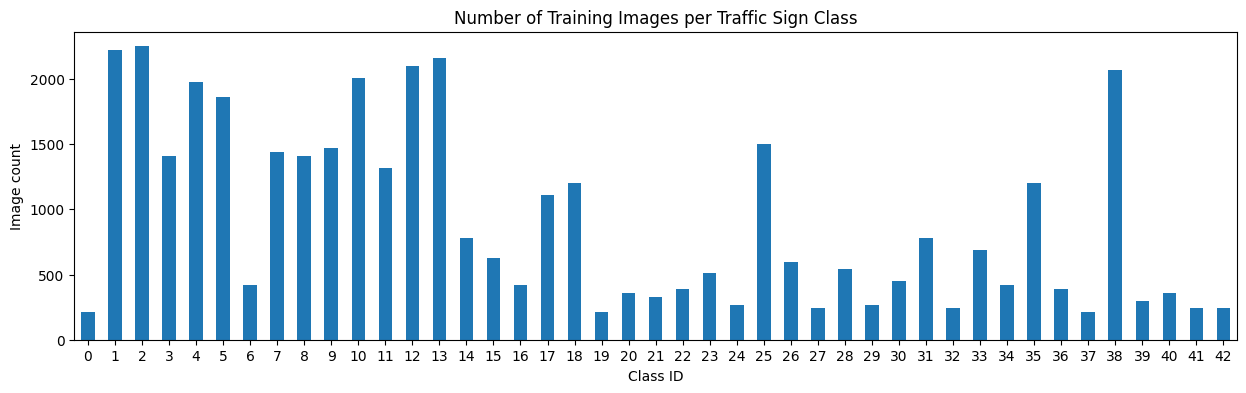

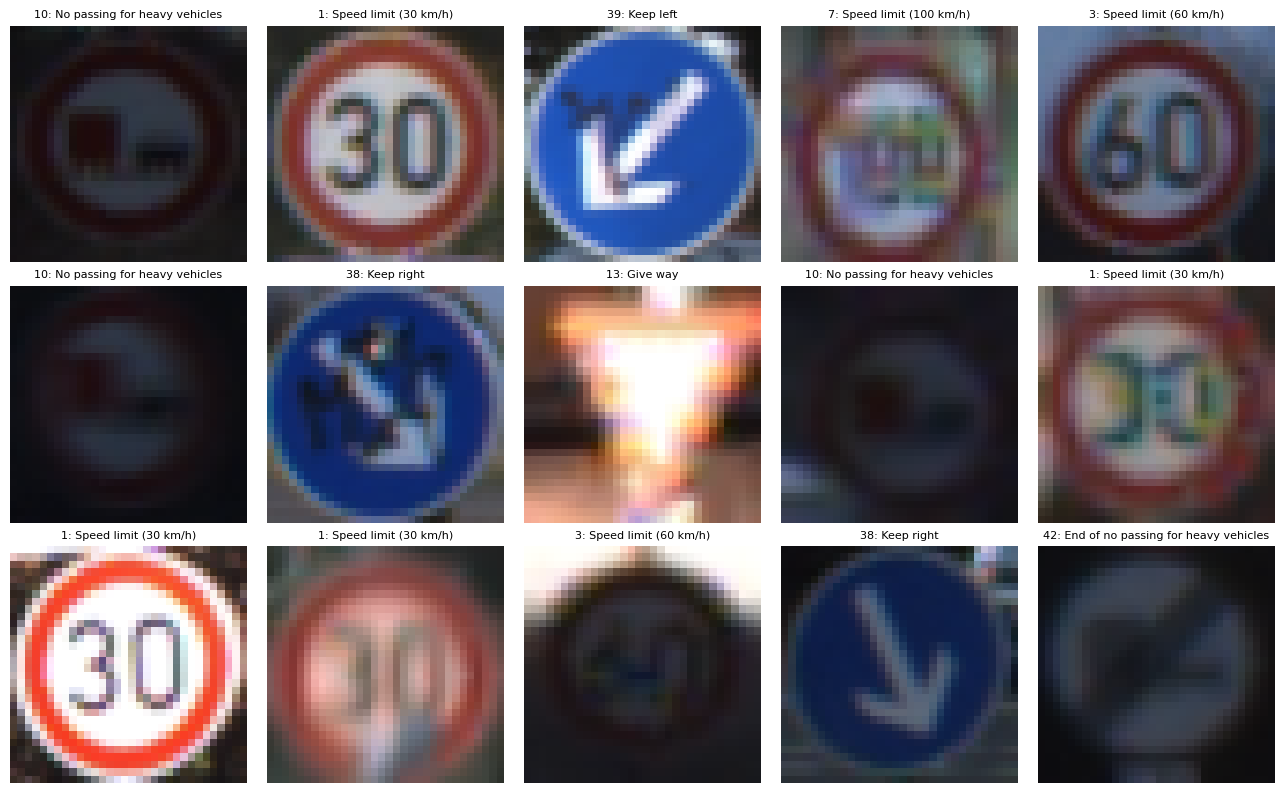

In [14]:
class_counts = pd.Series(y_train_all).value_counts().sort_index()
plt.figure(figsize=(15, 4))
class_counts.plot(kind="bar")
plt.title("Number of Training Images per Traffic Sign Class")
plt.xlabel("Class ID")
plt.ylabel("Image count")
plt.xticks(rotation=0)
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax in axes.flat:
    idx = np.random.randint(0, len(X_train_all_raw))
    ax.imshow(X_train_all_raw[idx])
    ax.set_title(f"{y_train_all[idx]}: {CLASS_NAMES[y_train_all[idx]]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Create training, validation, and test sets

The provided `Train.csv` and `Test.csv` are kept separate when `Test.csv` contains labels. A validation set is taken from the training data using `train_test_split`. If the downloaded test CSV has no `ClassId` column, the notebook instead creates a stratified test split from labeled training data; an unlabeled test CSV cannot be used to calculate test accuracy.

In [15]:
test_class_col = choose_column(test_df, ["ClassId", "ClassID", "Label", "Class"], required=False)

if test_class_col is not None:
    print("Test.csv has labels: using it as the held-out test set.")
    X_test_raw, y_test, test_image_paths = load_images(test_df, "Testing images")
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(
        X_train_all_raw,
        y_train_all,
        test_size=0.15,
        random_state=SEED,
        stratify=y_train_all
    )
else:
    print("Test.csv has no labels: making a held-out test split from Train.csv instead.")
    X_trainval_raw, X_test_raw, y_trainval, y_test = train_test_split(
        X_train_all_raw,
        y_train_all,
        test_size=0.20,
        random_state=SEED,
        stratify=y_train_all
    )
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(
        X_trainval_raw,
        y_trainval,
        test_size=0.15,
        random_state=SEED,
        stratify=y_trainval
    )
    test_image_paths = []

print("Training set:", X_train_raw.shape, y_train.shape)
print("Validation set:", X_val_raw.shape, y_val.shape)
print("Testing set:", X_test_raw.shape, y_test.shape)
print("Training classes:", len(np.unique(y_train)))

# Convert pixels from integer range [0, 255] to float range [0, 1].
X_train = X_train_raw.astype("float32") / 255.0
X_val = X_val_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

print("Normalized pixel range:", X_train.min(), "to", X_train.max())

# The source arrays are no longer needed after normalization; free their memory.
del X_train_all_raw, X_train_raw, X_val_raw, X_test_raw
if "X_trainval_raw" in globals():
    del X_trainval_raw


Test.csv has labels: using it as the held-out test set.


Testing images:   0%|          | 0/12630 [00:00<?, ?it/s]

Training set: (33327, 32, 32, 3) (33327,)
Validation set: (5882, 32, 32, 3) (5882,)
Testing set: (12630, 32, 32, 3) (12630,)
Training classes: 43
Normalized pixel range: 0.0 to 1.0


## 9. Build a deeper CNN model

This model is intentionally built from standard Keras layers, not a prebuilt detection framework. It uses three convolutional blocks to learn increasingly complex visual features, dropout to help limit overfitting, and a 43-unit softmax output for multiclass classification.

In [16]:
model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Block 1: simple edges, colors, and shapes
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.20),

    # Block 2: more detailed visual patterns
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3: higher-level sign features
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,019 (2.57 MB)

 Trainable params: 675,019 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

## 10. Train the CNN

In [17]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# The dataset has uneven class counts, so balanced weights can reduce bias toward frequent classes.
classes_in_train = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_in_train,
    y=y_train
)
class_weights = dict(zip(classes_in_train.tolist(), weights.tolist()))

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)


Epoch 1/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.4084 - loss: 2.0421 - val_accuracy: 0.8914 - val_loss: 0.4384 - learning_rate: 0.0010
Epoch 2/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8730 - loss: 0.3566 - val_accuracy: 0.9769 - val_loss: 0.0919 - learning_rate: 0.0010
Epoch 3/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9396 - loss: 0.1731 - val_accuracy: 0.9827 - val_loss: 0.0690 - learning_rate: 0.0010
Epoch 4/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9565 - loss: 0.1240 - val_accuracy: 0.9908 - val_loss: 0.0415 - learning_rate: 0.0010
Epoch 5/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9637 - loss: 0.1002 - val_accuracy: 0.9920 - val_loss: 0.0310 - learning_rate: 0.0010
Epoch 6/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9687 - loss: 0.0863 - val_accuracy: 0.9935 - val_loss: 0.0294 - learning_rate: 0.0010
Epoch 7/30
521/521 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9753 - loss: 0.0658 

## 11. Plot training and validation accuracy/loss

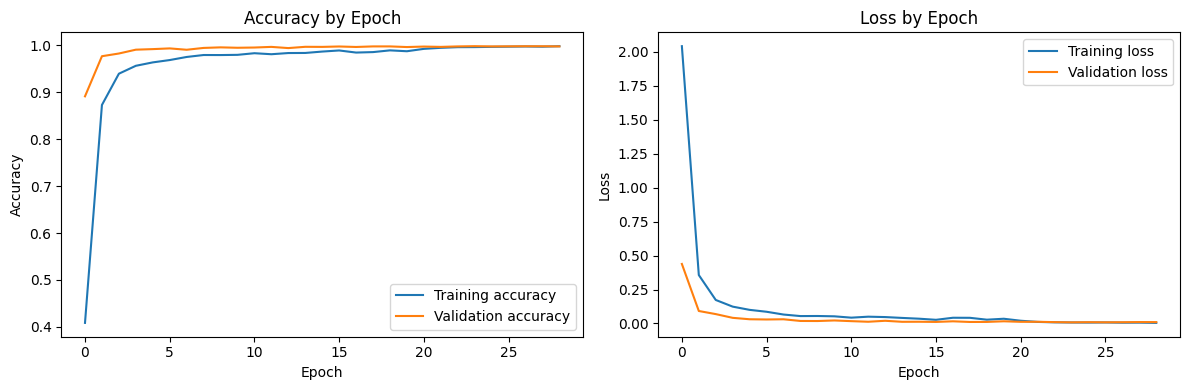

In [18]:
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_df["accuracy"], label="Training accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_df["loss"], label="Training loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.title("Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Evaluate on the held-out test set

In [19]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Test loss:             {test_loss:.4f}")
print(f"Test accuracy:         {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro precision:       {precision_macro:.4f}")
print(f"Macro recall:          {recall_macro:.4f}")
print(f"Macro F1-score:        {f1_macro:.4f}")
print(f"Weighted F1-score:     {f1_weighted:.4f}")

print("\nClassification report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))


99/99 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step
Test loss:             0.1172
Test accuracy:         0.9807 (98.07%)
Macro precision:       0.9649
Macro recall:          0.9629
Macro F1-score:        0.9624
Weighted F1-score:     0.9806

Classification report:

                                      precision    recall  f1-score   support

               Speed limit (20 km/h)     1.0000    1.0000    1.0000        60
               Speed limit (30 km/h)     0.9876    0.9917    0.9896       720
               Speed limit (50 km/h)     0.9907    0.9973    0.9940       750
               Speed limit (60 km/h)     0.9954    0.9711    0.9831       450
               Speed limit (70 km/h)     0.9985    0.9924    0.9954       660
               Speed limit (80 km/h)     0.9439    0.9889    0.9659       630
        End of speed limit (80 km/h)     1.0000    0.8333    0.9091       150
              Speed limit (100 km/h)     0.9933    0.9956    0.9945       450
              Speed limit (120 km/h)     0.

## 13. Confusion matrix

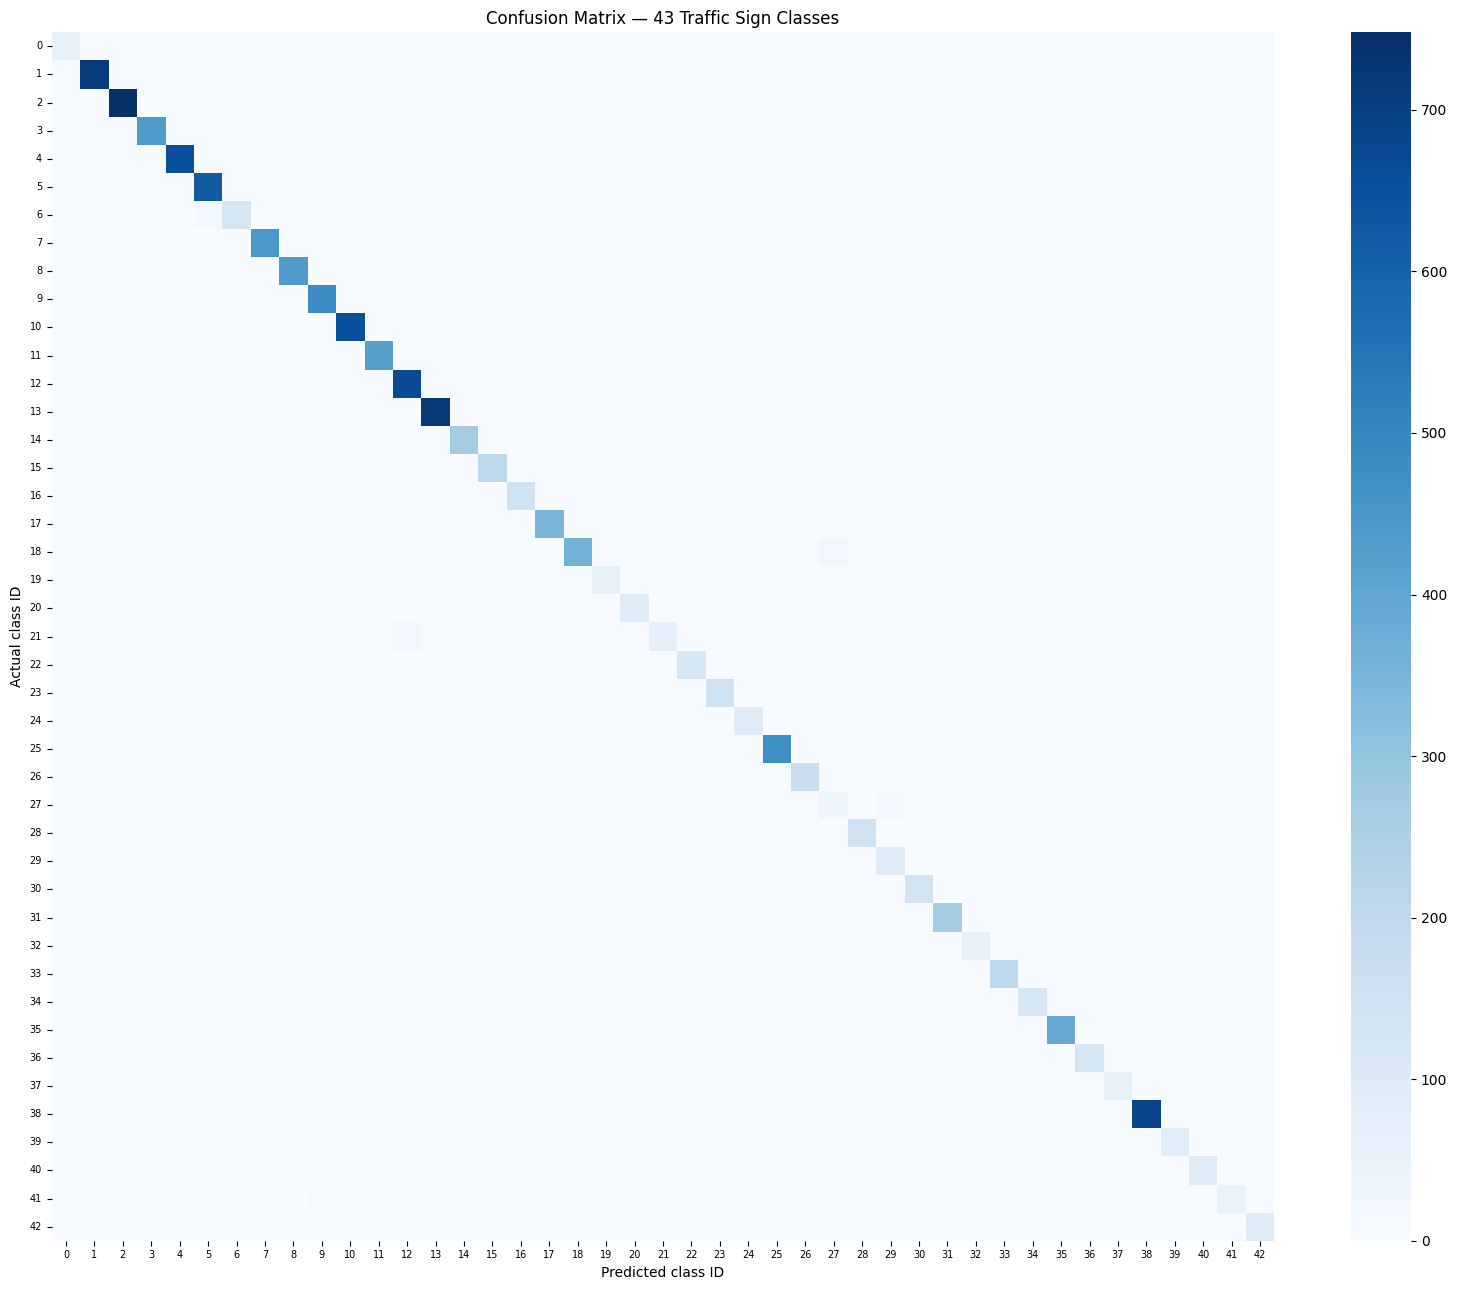

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap="Blues", annot=False, cbar=True)
plt.title("Confusion Matrix — 43 Traffic Sign Classes")
plt.xlabel("Predicted class ID")
plt.ylabel("Actual class ID")
plt.xticks(np.arange(NUM_CLASSES) + 0.5, np.arange(NUM_CLASSES), rotation=0, fontsize=7)
plt.yticks(np.arange(NUM_CLASSES) + 0.5, np.arange(NUM_CLASSES), rotation=0, fontsize=7)
plt.tight_layout()
plt.show()


## 14. Check predictions on a few test images

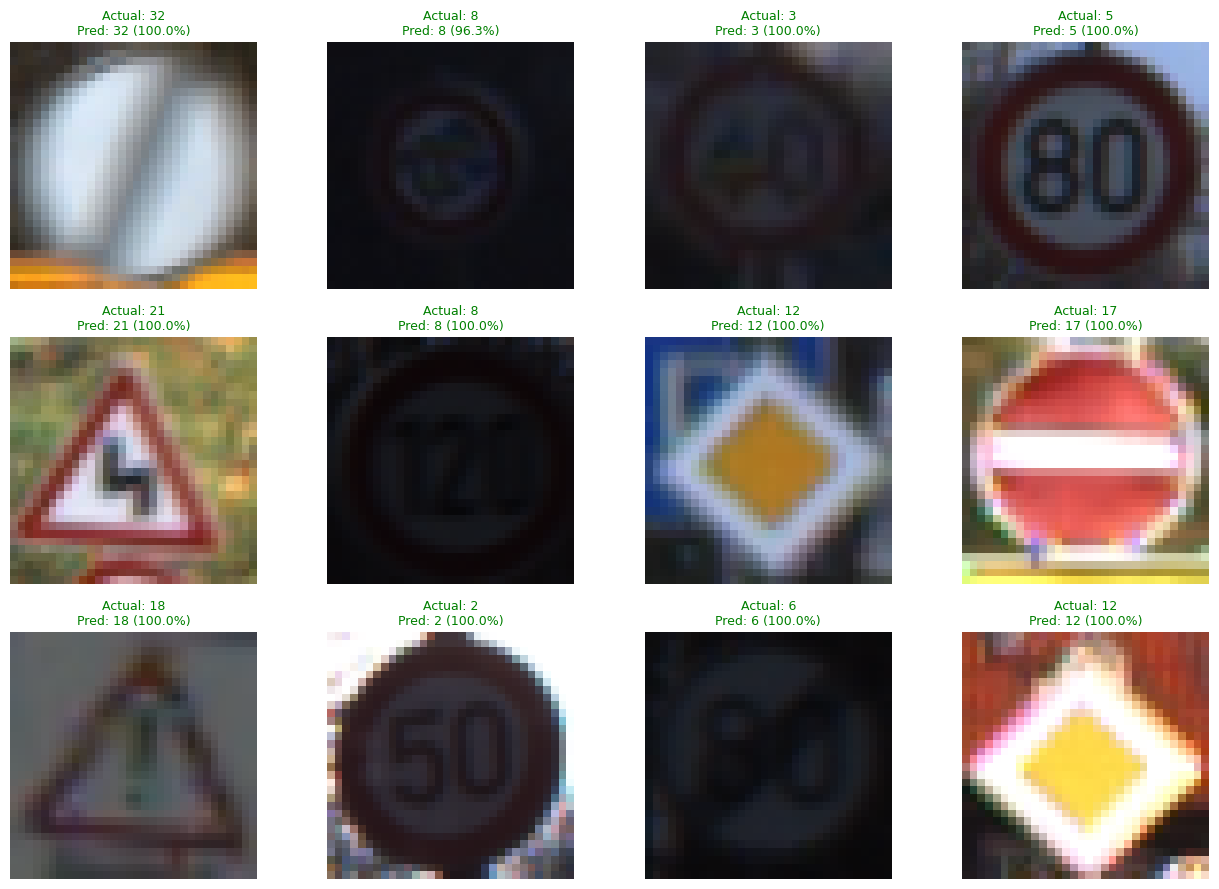

In [21]:
number_to_show = 12
sample_indices = np.random.choice(len(X_test), size=min(number_to_show, len(X_test)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for ax, idx in zip(axes.flat, sample_indices):
    actual_id = int(y_test[idx])
    predicted_id = int(y_pred[idx])
    confidence = float(np.max(probabilities[idx])) * 100
    ax.imshow(X_test[idx])
    ax.set_title(
        f"Actual: {actual_id}\nPred: {predicted_id} ({confidence:.1f}%)",
        color=("green" if actual_id == predicted_id else "red"),
        fontsize=9
    )
    ax.axis("off")
for ax in axes.flat[len(sample_indices):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 15. Predict one new traffic-sign image

Use a close-cropped image containing one traffic sign. The model was trained on ROI-cropped signs, so uploading a full road photograph with a tiny sign in the corner is not the intended input for this classifier. For a single image on your own computer, upload it to Colab or Drive and set the path below.

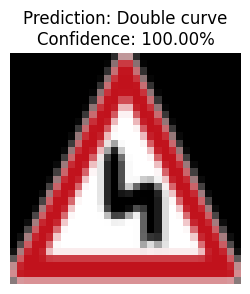

{'class_id': 21, 'class_name': 'Double curve', 'confidence': 1.0}


In [27]:
def predict_traffic_sign(image_path):
    """Predict the class of a single image containing one close-cropped traffic sign."""
    image_path = Path(image_path)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    with Image.open(image_path) as opened_image:
        image = opened_image.convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        image_array = np.asarray(image, dtype=np.float32) / 255.0

    probabilities_one = model.predict(np.expand_dims(image_array, axis=0), verbose=0)[0]
    predicted_id = int(np.argmax(probabilities_one))
    confidence = float(probabilities_one[predicted_id])

    plt.figure(figsize=(3, 3))
    plt.imshow(image_array)
    plt.axis("off")
    plt.title(f"Prediction: {CLASS_NAMES[predicted_id]}\nConfidence: {confidence:.2%}")
    plt.show()

    return {
        "class_id": predicted_id,
        "class_name": CLASS_NAMES[predicted_id],
        "confidence": confidence
    }

# Example: after uploading an image to Colab, set its path below.
prediction = predict_traffic_sign("/content/R.png")
print(prediction)

## 16. Save the trained model and results to Google Drive

In [28]:
OUTPUT_DIR = Path("/content/drive/MyDrive/TrafficSignProject/results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "traffic_sign_cnn.keras"
class_names_path = OUTPUT_DIR / "class_names.json"
metrics_path = OUTPUT_DIR / "test_metrics.json"
history_path = OUTPUT_DIR / "training_history.csv"
report_path = OUTPUT_DIR / "classification_report.csv"

model.save(model_path)
with open(class_names_path, "w", encoding="utf-8") as file:
    json.dump(CLASS_NAMES, file, indent=2)

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy),
    "macro_precision": float(precision_macro),
    "macro_recall": float(recall_macro),
    "macro_f1": float(f1_macro),
    "weighted_f1": float(f1_weighted),
    "num_classes": NUM_CLASSES,
    "image_size": IMG_SIZE
}
with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

history_df.to_csv(history_path, index=False)
report_dict = classification_report(
    y_test,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)
pd.DataFrame(report_dict).transpose().to_csv(report_path)

print("Saved model:", model_path)
print("Saved class names:", class_names_path)
print("Saved metrics:", metrics_path)
print("Saved training history:", history_path)
print("Saved classification report:", report_path)


Saved model: /content/drive/MyDrive/TrafficSignProject/results/traffic_sign_cnn.keras
Saved class names: /content/drive/MyDrive/TrafficSignProject/results/class_names.json
Saved metrics: /content/drive/MyDrive/TrafficSignProject/results/test_metrics.json
Saved training history: /content/drive/MyDrive/TrafficSignProject/results/training_history.csv
Saved classification report: /content/drive/MyDrive/TrafficSignProject/results/classification_report.csv
